## Imports

In [15]:
import re, io, zipfile, urllib.request
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

nltk.download("stopwords", quiet=True)

True

## Task 1: Download and load the dataset

In [16]:
try:
    url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
    data = urllib.request.urlopen(url).read()
    z = zipfile.ZipFile(io.BytesIO(data))
except Exception as e:
    print("Download failed, upload the zip manually:", e)
    from google.colab import files
    uploaded = files.upload()
    z = zipfile.ZipFile(io.BytesIO(uploaded[list(uploaded.keys())[0]]))

frames = []
for name in z.namelist():
    if name.endswith("_labelled.txt") and not name.split("/")[-1].startswith("._"):
        with z.open(name) as f:
            df_part = pd.read_csv(f, sep="\t", header=None,
                                  names=["text", "label"], quoting=3,
                                  encoding="latin-1")
            df_part["source"] = name.split("/")[-1].split("_")[0]
            frames.append(df_part)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
print(df.head())
print(df["label"].value_counts())

(3000, 3)
                                                text  label  source
0  So there is no way for me to plug it in here i...      0  amazon
1                        Good case, Excellent value.      1  amazon
2                             Great for the jawbone.      1  amazon
3  Tied to charger for conversations lasting more...      0  amazon
4                                  The mic is great.      1  amazon
label
0    1500
1    1500
Name: count, dtype: int64


## Task 2: Text preprocessing

In [17]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)


print(df[["text", "clean_text"]].head(5).to_string())

                                                                                 text                                                                         clean_text
0  So there is no way for me to plug it in here in the US unless I go by a converter.  so there is no way for me to plug it in here in the us unless i go by a converter
1                                                         Good case, Excellent value.                                                          good case excellent value
2                                                              Great for the jawbone.                                                              great for the jawbone
3     Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!         tied to charger for conversations lasting more than minutes major problems
4                                                                   The mic is great.                                                                   the

## Task 3: Explore the data


--- Positive examples ---
1                     Good case, Excellent value.
2                          Great for the jawbone.
4                               The mic is great.
7     If you are Razr owner...you must have this!
10                And the sound quality is great.

--- Negative examples ---
0    So there is no way for me to plug it in here i...
3    Tied to charger for conversations lasting more...
5    I have to jiggle the plug to get it to line up...
6    If you have several dozen or several hundred c...
8                  Needless to say, I wasted my money.

Top positive words: [('great', 201), ('good', 178), ('film', 105), ('phone', 88), ('movie', 86), ('one', 76), ('well', 68), ('best', 63), ('food', 60), ('place', 58)]
Top negative words: [('bad', 100), ('movie', 96), ('phone', 80), ('one', 70), ('like', 69), ('food', 66), ('time', 62), ('would', 59), ('film', 58), ('place', 56)]


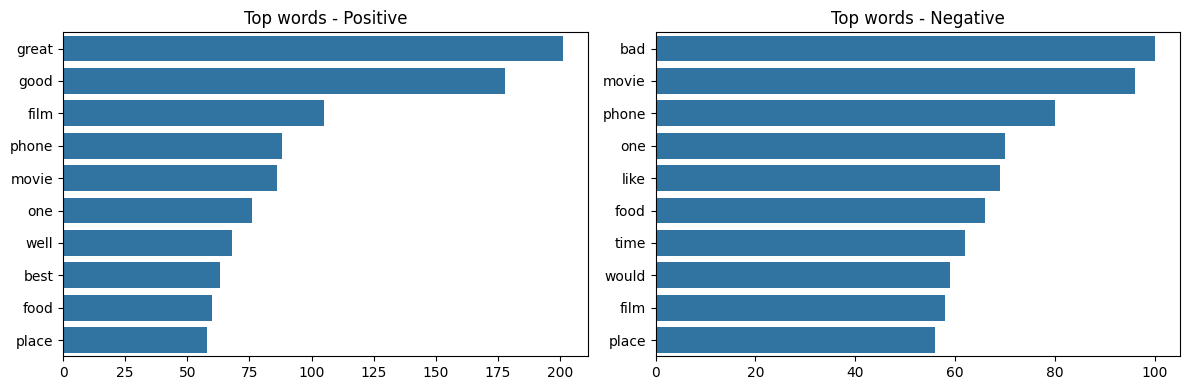

In [18]:
print("\n--- Positive examples ---")
print(df[df["label"] == 1]["text"].head(5).to_string())
print("\n--- Negative examples ---")
print(df[df["label"] == 0]["text"].head(5).to_string())

stop_words = set(stopwords.words("english"))

def top_words(texts, n=10):
    words = " ".join(texts).split()
    words = [w for w in words if w not in stop_words and len(w) > 2]
    return Counter(words).most_common(n)

pos_top = top_words(df[df["label"] == 1]["clean_text"])
neg_top = top_words(df[df["label"] == 0]["clean_text"])
print("\nTop positive words:", pos_top)
print("Top negative words:", neg_top)


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, words, title in zip(axes, [pos_top, neg_top], ["Positive", "Negative"]):
    w, c = zip(*words)
    sns.barplot(x=list(c), y=list(w), ax=ax)
    ax.set_title(f"Top words - {title}")
plt.tight_layout()
plt.show()



## Task 4: Split the dataset



In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.2,
    random_state=42, stratify=df["label"])
print(len(X_train), len(X_test))

2400 600


## Task 5: Bag of Words (BOW)

In [20]:
vectorizer = CountVectorizer(stop_words="english")
X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)
print("BOW shape:", X_train_bow.shape)

BOW shape: (2400, 4223)


## Task 6: Train ML models

In [21]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_bow, y_train)

svm = LinearSVC()
svm.fit(X_train_bow, y_train)

LinearSVC()

## Task 7: Evaluate (Accuracy, Precision, Recall, F1)


=== Logistic Regression ===
Accuracy : 0.81
Precision: 0.8039
Recall   : 0.82
F1-score : 0.8119
              precision    recall  f1-score   support

    Negative       0.82      0.80      0.81       300
    Positive       0.80      0.82      0.81       300

    accuracy                           0.81       600
   macro avg       0.81      0.81      0.81       600
weighted avg       0.81      0.81      0.81       600



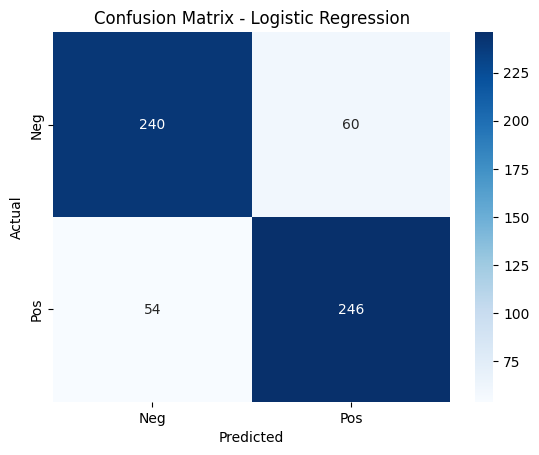


=== Linear SVM ===
Accuracy : 0.7883
Precision: 0.7629
Recall   : 0.8367
F1-score : 0.7981
              precision    recall  f1-score   support

    Negative       0.82      0.74      0.78       300
    Positive       0.76      0.84      0.80       300

    accuracy                           0.79       600
   macro avg       0.79      0.79      0.79       600
weighted avg       0.79      0.79      0.79       600



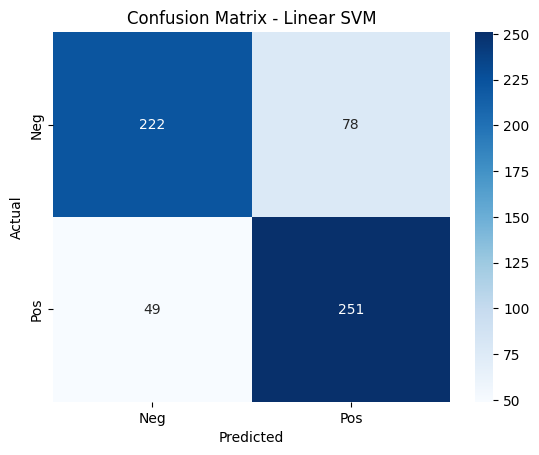

In [22]:
def evaluate(model, name):
    pred = model.predict(X_test_bow)
    print(f"\n=== {name} ===")
    print("Accuracy :", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred), 4))
    print("Recall   :", round(recall_score(y_test, pred), 4))
    print("F1-score :", round(f1_score(y_test, pred), 4))
    print(classification_report(y_test, pred, target_names=["Negative", "Positive"]))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.show()

evaluate(lr, "Logistic Regression")
evaluate(svm, "Linear SVM")

## Task 8: Test with new sentences

In [23]:
def predict_sentiment(sentence, model=lr):
    vec = vectorizer.transform([clean_text(sentence)])
    return "Positive" if model.predict(vec)[0] == 1 else "Negative"

tests = [
    "The food was absolutely amazing and the staff were friendly",
    "This phone is terrible, the battery dies in an hour",
    "The movie was boring and a complete waste of time",
]
for s in tests:
    print(f"{s!r} -> {predict_sentiment(s)}")

'The food was absolutely amazing and the staff were friendly' -> Positive
'This phone is terrible, the battery dies in an hour' -> Negative
'The movie was boring and a complete waste of time' -> Negative


### Key Observations
1. **Vocabulary:**
   Positive reviews use words like "great", "good", "love" and "best". Negative ones use "bad", "terrible", "waste" and "boring". Topic nouns like "movie", "phone" and "place" appear in both classes, so they carry little sentiment.

2. **Model comparison**
   - **Logistic Regression**accuracy 81.0%, F1 0.81, balanced precision and recall.

   - **Linear SVM**accuracy 78.83%, F1 ~0.80, higher positive recall (84%) but lower positive precision.

  
3.  **Conclusion:**
    - Logistic Regression performed slightly better and more evenly on this BOW representation.

4. **Limitation:**
    - BOW ignores word order and context (for example, negation), which can cause wrong predictions on new sentences.